### Graph Correlators

### MAE Plot

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 

results_df = pd.read_csv('./graph_correlator_comparison.csv')
methods = [
        "Product",
        "DQC+ProdEM_m15",
        "DQC+ProdEM_m18",
        "DQC+ProdEM_m21",
        "DQC+LocalCondEM_m15",
        "DQC+LocalCondEM_m18",
        "DQC+LocalCondEM_m21",
        "DQC_m15",
        "DQC_m18",
        "DQC_m21"
    ]

# Product run_idx is assigned sequentially from its 150 loaded sets.
# Keep the first 50 for each circuit and observable group.
results_df = results_df.loc[
    (results_df["method"] != "Product")
    | (results_df["run_idx"] < 50)
].copy()

# Check the number of repetitions for every combination.
counts = results_df.groupby(["model", "method", "group"]).size()
if not counts.eq(50).all():
    raise ValueError(
        f"Expected 50 repetitions per combination:\n{counts[counts != 50]}"
    )
methods = [
    "Product",
    "DQC+ProdEM_m15",
    "DQC+ProdEM_m18",
    "DQC+ProdEM_m21",
    "DQC+LocalCondEM_m15",
    "DQC+LocalCondEM_m18",
    "DQC+LocalCondEM_m21",
    "DQC_m15",
    "DQC_m18",
    "DQC_m21",
]

groups = [
    "edge_w2",
    "distance2_w2",
    "nonlocal_w2",
    "connected_w3",
    "connected_w4",
]

models = sorted(results_df["model"].unique())
rng = np.random.default_rng(42)
num_bootstrap = 5000
rows = []

for group in groups:
    for method in methods:
        selected = results_df[
            (results_df["group"] == group)
            & (results_df["method"] == method)
        ]

        circuit_means = []
        bootstrap_means = np.zeros(num_bootstrap)

        for model in models:
            model_rows = (
                selected[selected["model"] == model]
                .sort_values("run_idx")
            )

            if model_rows["run_idx"].duplicated().any():
                raise ValueError(
                    f"Duplicate repetitions: {model}, {method}, {group}"
                )

            errors = model_rows["error"].to_numpy(dtype=float)

            if len(errors) != 50:
                raise ValueError(
                    f"Expected 50 repetitions for "
                    f"{model}, {method}, {group}; got {len(errors)}."
                )

            if not np.all(np.isfinite(errors)):
                raise ValueError(
                    f"Nonfinite errors: {model}, {method}, {group}"
                )

            circuit_means.append(errors.mean())

            # Resample repetitions within this circuit.
            indices = rng.integers(
                0, len(errors),
                size=(num_bootstrap, len(errors)),
            )

            # Each circuit receives equal weight.
            bootstrap_means += (
                errors[indices].mean(axis=1) / len(models)
            )

        rows.append({
            "Group": group,
            "Method": method,
            "Error Mean": float(np.mean(circuit_means)),
            "Error ci95": np.quantile(
                bootstrap_means, [0.025, 0.975]
            ),
        })

paper_df = pd.DataFrame(rows)
paper_df

,Group,Method,Error Mean,Error ci95
0,edge_w2,Product,0.041626,"[0.041042574735091, 0.04218231704030109]"
1,edge_w2,DQC+ProdEM_m15,0.034969,"[0.03441936440242991, 0.03553510625732108]"
2,edge_w2,DQC+ProdEM_m18,0.034245,"[0.03361949024098945, 0.03486794804853098]"
3,edge_w2,DQC+ProdEM_m21,0.033497,"[0.03296226632167109, 0.03404119096531238]"
4,edge_w2,DQC+LocalCondEM_m15,0.031424,"[0.0308969172425185, 0.031931479746329545]"
5,edge_w2,DQC+LocalCondEM_m18,0.031315,"[0.030802858617224264, 0.031839925583023676]"
6,edge_w2,DQC+LocalCondEM_m21,0.031504,"[0.03098057109083252, 0.032014106749418174]"
7,edge_w2,DQC_m15,0.148625,"[0.14773771933116348, 0.14952299721202542]"
8,edge_w2,DQC_m18,0.124900,"[0.12396326703634787, 0.1258561662631271]"
9,edge_w2,DQC_m21,0.109044,"[0.10813401500193606, 0.10990031247244643]"


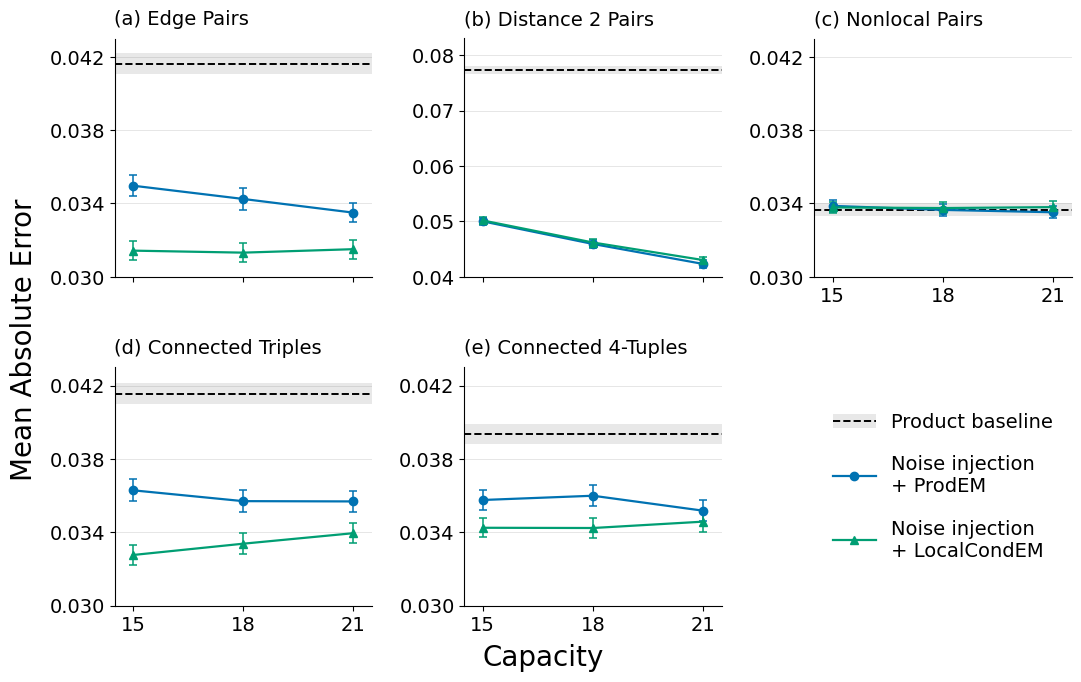

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.legend_handler import HandlerTuple
from matplotlib.ticker import MaxNLocator

METHOD_COLORS = {
    "DQC+ProdEM": "#0072B2",
    "DQC+LocalCondEM": "#009E73",
    "Product": "#000000",
}

METHOD_LABELS = {
    "DQC+ProdEM": "Noise injection + ProdEM",
    "DQC+LocalCondEM": "Noise injection + LocalCondEM",
}

GROUP_NAMES = {
    "edge_w2": "Edge Pairs",
    "distance2_w2": "Distance 2 Pairs",
    "nonlocal_w2": "Nonlocal Pairs",
    "connected_w3": "Connected Triples",
    "connected_w4": "Connected 4-Tuples",
}

MARKERS = {
    "DQC+ProdEM": "o",
    "DQC+LocalCondEM": "^",
}

methods = ["DQC+ProdEM", "DQC+LocalCondEM"]
capacities = [15, 18, 21]

fig, axes = plt.subplots(
    2, 3,
    sharex=True,
    sharey=False,
    figsize=(11, 7),
)

for gi, (group, title) in enumerate(GROUP_NAMES.items()):
    ax = axes.flat[gi]
    group_df = (
        paper_df[paper_df["Group"] == group]
        .set_index("Method")
    )

    # Product baseline mean and confidence interval.
    baseline = group_df.loc["Product"]
    baseline_mean = float(baseline["Error Mean"])
    baseline_low, baseline_high = baseline["Error ci95"]

    ax.axhspan(
        baseline_low,
        baseline_high,
        color="0.5",
        alpha=0.18,
        linewidth=0,
        zorder=1,
    )
    ax.axhline(
        baseline_mean,
        color=METHOD_COLORS["Product"],
        linestyle="--",
        linewidth=1.4,
        zorder=2,
    )

    for method in methods:
        rows = group_df.loc[
            [f"{method}_m{capacity}" for capacity in capacities]
        ]

        means = rows["Error Mean"].to_numpy(dtype=float)
        ci95s = np.asarray(rows["Error ci95"].tolist(), dtype=float)

        yerrs = np.vstack([
            means - ci95s[:, 0],
            ci95s[:, 1] - means,
        ])

        ax.errorbar(
            capacities,
            means,
            yerr=yerrs,
            color=METHOD_COLORS[method],
            marker=MARKERS[method],
            markersize=6,
            linewidth=1.6,
            elinewidth=1.1,
            capsize=3,
            capthick=1.1,
            label=METHOD_LABELS[method],
            zorder=3,
        )

    ax.set_title(
        f"({chr(97 + gi)}) {title}",
        fontsize=14,
        loc="left",
        pad=10,
    )
    ax.set_xlim(14.5, 21.5)
    ax.set_xticks(capacities)
    ax.tick_params(axis="both", labelsize=14)

    if group == "distance2_w2":
        ax.set_ylim(0.04, 0.083)
        ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
    else:
        ax.set_ylim(0.03, 0.043)
        ax.set_yticks([0.030, 0.034, 0.038, 0.042])

    ax.set_axisbelow(True)
    ax.grid(axis="y", color="0.90", linewidth=0.7)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# Show capacity labels beneath the nonlocal panel.
axes[0, 2].tick_params(labelbottom=True)

# Baseline legend entry combines the band and dashed mean.
baseline_handle = (
    Patch(facecolor="0.5", alpha=0.18, edgecolor="none"),
    Line2D([0], [0], color="black", linestyle="--", linewidth=1.4),
)

method_handles = [
    Line2D(
        [0], [0],
        color=METHOD_COLORS[method],
        marker=MARKERS[method],
        markersize=6,
        linewidth=1.6,
    )
    for method in methods
]

# Wrap long labels to fit the unused panel.
legend_labels = [
    "Product baseline",
    "Noise injection\n+ ProdEM",
    "Noise injection\n+ LocalCondEM",
]

axes[1, 2].legend(
    [baseline_handle] + method_handles,
    legend_labels,
    handler_map={tuple: HandlerTuple(ndivide=1)},
    loc="center",
    frameon=False,
    fontsize=14,
    handlelength=2.2,
    labelspacing=1.2,
)
axes[1, 2].set_axis_off()

fig.supxlabel("Capacity", fontsize=20, y=0.025)
fig.supylabel("Mean Absolute Error", fontsize=20, x=0.015)

fig.subplots_adjust(
    left=0.11,
    right=0.98,
    bottom=0.12,
    top=0.93,
    wspace=0.36,
    hspace=0.38,
)

fig.savefig("graph_correlators_EMonly.pdf", bbox_inches="tight")
plt.show()